<a href="https://colab.research.google.com/github/fat-panda-wasib/Attitudes-toward-immigration-in-Italy-Europe/blob/main/Attitudes_toward_immigration_in_Italy_Europe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Attitudes toward immigration in Italy/Europe — what predicts anti-immigrant attitudes?

## Research Question

*What socioeconomic and political factors predict anti-immigrant attitudes among Italians?*

In [ ]:
!pip install pingouin  # For Cronbach's alpha

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.gofplots import ProbPlot
import pingouin as pg

# Set visual style
sns.set_theme(style="whitegrid")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 4.6 MB/s eta 0:00:00


In [ ]:
# LOAD DATA
# IMPORTANT: Adjust the filename if yours is different

df = pd.read_csv("/content/sample_data/ESS11e04_2.csv", low_memory=False)

In [ ]:
# FILTER FOR ITALY ONLY
# ESS usually uses 'cntry', but data file uses 'entry'. Keep 'entry' as per your code.

italy = df[df["cntry"] == "IT"].copy()
print(f"Original Italian respondents: {len(italy)}")

Original Italian respondents: 2865


In [ ]:
# SELECT RELEVANT VARIABLES (Added 'dweight' for weighting)

vars_needed = [
    "imwbcnt",      # outcome: immigration makes country worse/better (0-10)
    "imueclt",      # outcome component: cultural impact (common alternative for imucelt)
    "imbgeco",      # outcome component: economic impact
    "gndr",         # gender (1=male, 2=female)
    "agea",         # age (continuous)
    "eduyrs",       # years of education (continuous)
    "hinctnta",     # household income decile (1-10)
    "lrscale",      # left-right political scale (0=left, 10=right)
    "trstplt",      # trust in politicians (0-10)
    "domicil",      # urban/rural (1=big city > 5=rural)
    "dweight"       # <--- DESIGN WEIGHT (CRITICAL FOR REPRESENTATIVENESS)
]

italy = italy[vars_needed].copy()

# Rename for readability
italy.columns = [
    "immig_general", "immig_cultural", "immig_economic",
    "gender", "age", "education", "income",
    "left_right", "trust_politicians", "urban_rural",
    "dweight"
]

print(italy.head())

       immig_general  immig_cultural  immig_economic  gender  age  education  \
29034              4               4               4       1   39         13   
29035              7               7               7       2   29         16   
29036              3               6               5       2   47         11   
29037              3               2               4       2   21         14   
29038              3              88              88       1   62         77   

       income  left_right  trust_politicians  urban_rural   dweight  
29034      77           6                  5            4  0.934106  
29035       6           4                  3            3  0.881058  
29036       4           7                  4            4  0.938100  
29037      88           8                  5            4  1.003541  
29038      88           8                  5            4  0.955288  


In [ ]:
# HANDLE MISSING VALUES (CRITICAL FIX)
# ESS uses 77, 88, 99, 777, 888, 999, etc. for refusals/don't know.

special_codes = [77, 88, 99, 777, 888, 999, 7777, 8888, 9999]
italy.replace(special_codes, np.nan, inplace=True)

# Drop rows with any missing values in the variables we'll use for regression

italy.dropna(inplace=True)
print(f"Clean sample size after dropping missing: {len(italy)}")

# CREATE DEPENDENT VARIABLE & TRANSFORMATIONS
# Reverse code so HIGHER score = MORE anti-immigrant (0=Pro, 10=Anti)

italy["anti_immig"] = (
    (10 - italy["immig_general"]) +
    (10 - italy["immig_cultural"]) +
    (10 - italy["immig_economic"])
) / 3

# Recode gender: 1=male, 0=female

italy["male"] = (italy["gender"] == 1).astype(int)

# Center age to reduce multicollinearity (mean age is around 52)

italy["age_centered"] = italy["age"] - italy["age"].mean()
italy["age_centered_sq"] = italy["age_centered"] ** 2

Clean sample size after dropping missing: 1441


In [ ]:
# RELIABILITY CHECK (Cronbach's Alpha)

print("\n--- Cronbach's Alpha for the 3-item scale ---")
alpha = pg.cronbach_alpha(data=italy[["immig_general", "immig_cultural", "immig_economic"]])
print(f"Cronbach's Alpha: {alpha[0]:.3f} (Good if > 0.7)")


--- Cronbach's Alpha for the 3-item scale ---
Cronbach's Alpha: 0.887 (Good if > 0.7)


In [ ]:
# DESCRIPTIVE STATISTICS (FIXED SYNTAX)

print("\n--- Descriptive Statistics ---")
# FIXED: Use double brackets [[]] to select multiple columns
desc_vars = ["anti_immig", "age", "education", "income", "left_right", "trust_politicians"]
print(italy[desc_vars].describe())


--- Descriptive Statistics ---
        anti_immig          age    education       income   left_right  \
count  1441.000000  1441.000000  1441.000000  1441.000000  1441.000000   
mean      4.975017    52.256072    12.212353     5.403192     5.089521   
std       2.139212    18.468038     4.289443     2.355954     2.171381   
min       0.000000    15.000000     0.000000     1.000000     0.000000   
25%       3.333333    38.000000     8.000000     3.000000     4.000000   
50%       5.000000    52.000000    13.000000     5.000000     5.000000   
75%       6.333333    67.000000    14.000000     7.000000     7.000000   
max      10.000000    90.000000    45.000000    10.000000    10.000000   

       trust_politicians  
count        1441.000000  
mean            3.662734  
std             2.240735  
min             0.000000  
25%             2.000000  
50%             4.000000  
75%             5.000000  
max            10.000000  


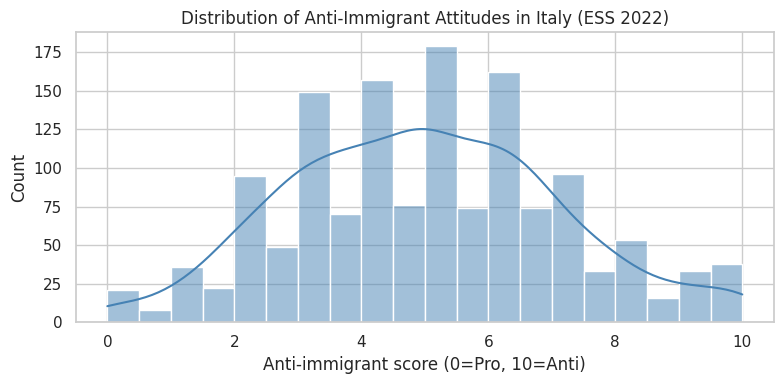

In [ ]:
# Distribution of anti-immigrant attitudes
plt.figure(figsize=(8, 4))
sns.histplot(italy["anti_immig"], bins=20, color="steelblue", kde=True)
plt.title("Distribution of Anti-Immigrant Attitudes in Italy (ESS 2022)")
plt.xlabel("Anti-immigrant score (0=Pro, 10=Anti)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("distribution.png", dpi=150)
plt.show()

/tmp/ipykernel_525/960367705.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=italy, x="edu_group", y="anti_immig", palette="Blues")


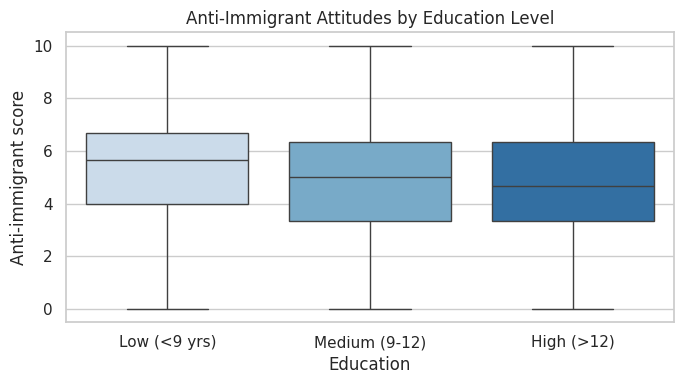

In [ ]:
# By Education Level (grouped)
italy["edu_group"] = pd.cut(italy["education"],
                            bins=[0, 9, 12, 30],
                            labels=["Low (<9 yrs)", "Medium (9-12)", "High (>12)"])

plt.figure(figsize=(7, 4))
sns.boxplot(data=italy, x="edu_group", y="anti_immig", palette="Blues")
plt.title("Anti-Immigrant Attitudes by Education Level")
plt.xlabel("Education")
plt.ylabel("Anti-immigrant score")
plt.tight_layout()
plt.savefig("education_boxplot.png", dpi=150)
plt.show()

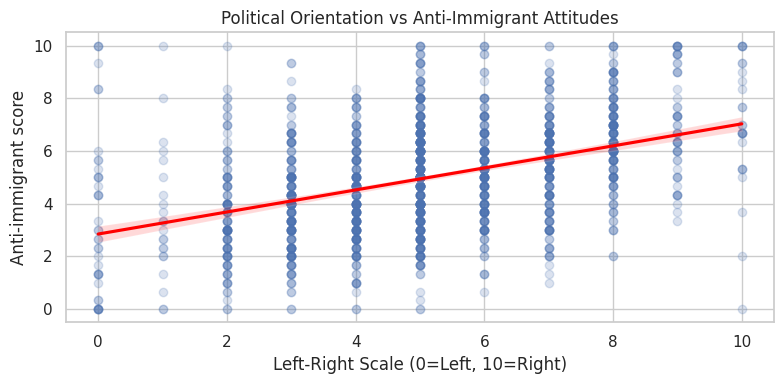

In [ ]:
# By Left-Right Political Position
plt.figure(figsize=(8, 4))
sns.regplot(data=italy, x="left_right", y="anti_immig",
            scatter_kws={"alpha": 0.2}, line_kws={"color": "red"})
plt.title("Political Orientation vs Anti-Immigrant Attitudes")
plt.xlabel("Left-Right Scale (0=Left, 10=Right)")
plt.ylabel("Anti-immigrant score")
plt.tight_layout()
plt.savefig("left_right_scatter.png", dpi=150)
plt.show()

In [ ]:
# MULTIVARIATE REGRESSION (WITH WEIGHTS!)
# Define predictors (X) and outcome (y)
X = italy[["male", "age", "age_centered_sq", "education", "income",
           "left_right", "trust_politicians", "urban_rural"]]
y = italy["anti_immig"]
weights = italy["dweight"]  # <-- Applying survey weights

# Add constant (intercept)
X = sm.add_constant(X)

# Run WEIGHTED Least Squares (WLS) for representativeness
# If you prefer UNWEIGHTED for simplicity, replace WLS with OLS below.
# model = sm.OLS(y, X).fit()   # Uncomment this line if you want OLS instead.
model = sm.WLS(y, X, weights=weights).fit()

print("\n--- Regression Results (Weighted) ---")
print(model.summary())


--- Regression Results (Weighted) ---
                            WLS Regression Results                            
Dep. Variable:             anti_immig   R-squared:                       0.261
Model:                            WLS   Adj. R-squared:                  0.257
Method:                 Least Squares   F-statistic:                     63.21
Date:                Fri, 24 Jul 2026   Prob (F-statistic):           1.03e-88
Time:                        05:06:46   Log-Likelihood:                -2950.8
No. Observations:                1441   AIC:                             5920.
Df Residuals:                    1432   BIC:                             5967.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------

In [ ]:
# MULTICOLLINEARITY CHECK (VIF)

print("\n--- Variance Inflation Factor (VIF) ---")
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data)
# Note: VIF > 10 indicates high multicollinearity. age and age_sq will be high,
# but that's expected. Keep age_sq for non-linearity.


--- Variance Inflation Factor (VIF) ---
            Variable        VIF
0              const  55.298971
1               male   1.009441
2                age   1.247646
3    age_centered_sq   1.048191
4          education   1.432918
5             income   1.139089
6         left_right   1.032870
7  trust_politicians   1.025535
8        urban_rural   1.034950


In [ ]:
# REGRESSION DIAGNOSTIC PLOTS
# Get fitted values and residuals
fitted = model.fittedvalues
residuals = model.resid

Text(0.5, 1.0, 'Residuals vs Fitted')

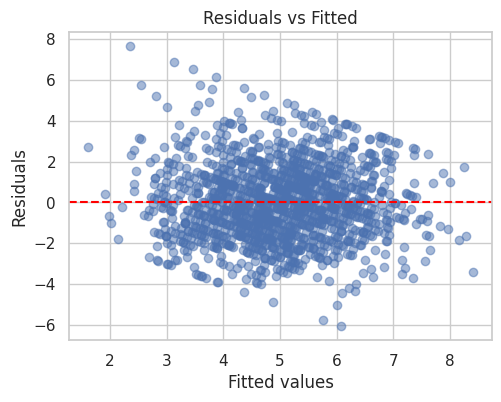

In [ ]:
# Residuals vs Fitted (check homoscedasticity)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.scatter(fitted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")

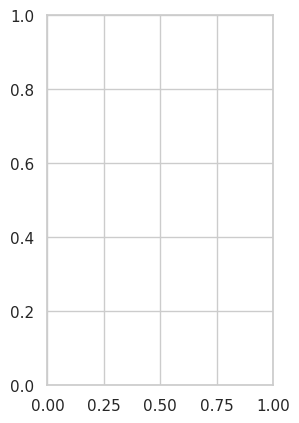

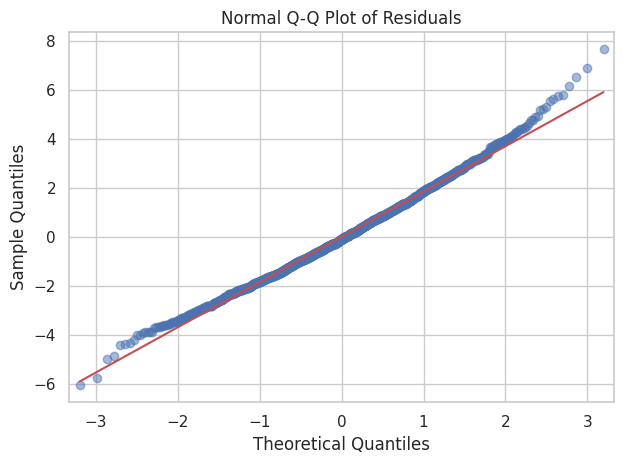

In [ ]:
# Q-Q plot (check normality of residuals)
plt.subplot(1, 2, 2)
qq = ProbPlot(residuals)
qq.qqplot(line='s', alpha=0.5)
plt.title("Normal Q-Q Plot of Residuals")
plt.tight_layout()
plt.savefig("diagnostics.png", dpi=150)
plt.show()